# Taller: Arquitectura de una Red Neuronal

### Redes Neuronales — Neurona artificial, capas, pesos, sesgos y forward pass con NumPy

**Pontificia Universidad Católica del Ecuador · Carrera de Ingeniería de Sistemas de Información**

**Asignatura:** Inteligencia Artificial · Sexto Semestre

**Nombre del estudiante:** Paúl Rosero

**Fecha:** 05-11-2026


> **Cómo usar este documento:** este archivo es una **guía de referencia**, no un notebook interactivo.
> Reproduce el código en tu propio notebook (Google Colab o Jupyter), en el mismo orden de bloques,
> usando los archivos CSV que se entregan junto con esta guía. Las respuestas a las preguntas
> se escriben en celdas de texto de **tu** notebook.


## Objetivos del taller

Al finalizar este taller el estudiante será capaz de:

1. Construir `X` e `y` desde un DataFrame y **normalizar** las entradas con min-max.
2. Definir los **pesos y sesgos** de una red con las dimensiones correctas y contar sus parámetros.
3. Programar el **forward pass** capa a capa (combinación lineal + ReLU + sigmoide) **solo con NumPy**.
4. Comparar una red **con y sin capa oculta** sobre datos reales.


## Datasets (sintéticos, sin valores nulos)

| Parte | Archivo | Filas | Entradas | Etiqueta |
| --- | --- | --- | --- | --- |
| A | estudiantes_aprobacion.csv | 200 estudiantes | horas_estudio, asistencia_pct | aprueba (1 = aprueba) |
| B | solicitudes_credito.csv | 200 solicitudes | ingresos_mensuales, deuda_total, historial_pagos | aprobado (1 = aprobado) |


## Estructura del taller

| Bloque | Tipo | Contenido |
| --- | --- | --- |
| A1 | Guiado | Carga y exploración de los datos |
| A2 | Guiado | Construir X, y y normalizar |
| A3 | Guiado | Arquitectura 2 → 2 → 1: pesos, sesgos y número de parámetros |
| A4 | Guiado | Funciones de activación ReLU y sigmoide |
| A5 | Guiado | Forward pass de la fila 0 |
| A6 | Guiado | Forward pass de las primeras 5 filas |
| A7 | Guiado | Predicciones para los 200 estudiantes |
| A8 | Guiado | Red sin capa oculta: comparación |
| B1–B5 | Autónomo | Red para solicitudes de crédito (3 entradas) |

## Rúbrica de evaluación (10 puntos)

| Componente | Qué se evalúa | Puntos |
| --- | --- | --- |
| Bloques A1–A8 (guiados) | Reproducidos completos y sin errores en tu notebook + respuestas a las preguntas de la Parte A | 1.5 |
| B1 · Carga y exploración | Código correcto + lectura del balance de clases | 1.0 |
| B2 · X_b, y_b y normalización | Código correcto + formas verificadas | 1.0 |
| B3 · Arquitectura y pesos | Dimensiones correctas + número de parámetros + justificación de la capa oculta | 2.5 |
| B4 · Forward pass | Fila 0 y tabla de 5 filas correctas | 2.0 |
| B5 · Comparación y reflexión | Accuracy con y sin capa oculta + respuestas de reflexión | 2.0 |
| **Total** | | **10** |


# Parte A — Laboratorio Guiado: ¿Aprobará el Estudiante?


En esta parte construimos una red neuronal **2 → 2 → 1** paso a paso, **solo con NumPy**.
No usamos scikit-learn ni Keras: el objetivo es ver exactamente qué ocurre en cada capa.
Los pesos son los mismos del ejemplo numérico de las diapositivas, así que puedes comparar cada resultado.


## Bloque A1 · Carga y exploración de los datos

**Librerías:** `numpy` (cálculo con vectores y matrices), `pandas` (datos) y `matplotlib.pyplot` (gráficos).

* `horas_estudio`: horas de estudio por semana.
* `asistencia_pct`: porcentaje de asistencia a clases.
* `aprueba`: etiqueta real (1 = aprueba, 0 = no aprueba).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("estudiantes_aprobacion.csv")
print("Filas y columnas:", df.shape)
df.head()


Filas y columnas: (200, 3)


,horas_estudio,asistencia_pct,aprueba
0,4.4,78.5,0
1,9.6,45.0,1
2,7.6,49.7,0
3,6.4,93.9,1
4,2.4,76.4,0


In [2]:
print(df["aprueba"].value_counts())
df.describe().round(1)


aprueba
0    117
1     83
Name: count, dtype: int64


,horas_estudio,asistencia_pct,aprueba
count,200.0,200.0,200.0
mean,5.4,70.3,0.4
std,2.7,17.6,0.5
min,1.0,40.3,0.0
25%,3.1,55.7,0.0
50%,5.4,72.5,0.0
75%,7.8,84.5,1.0
max,9.9,99.4,1.0


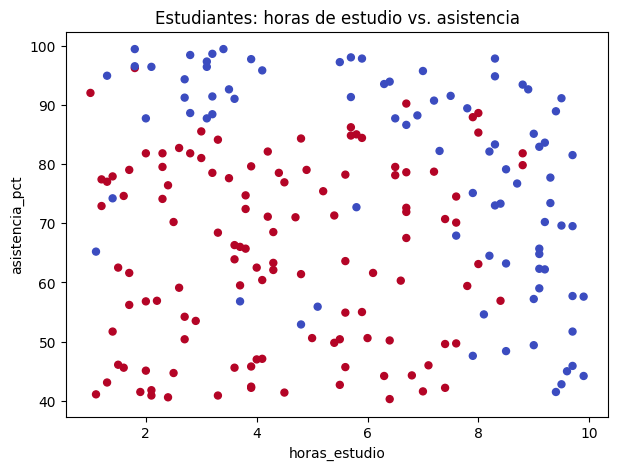

In [3]:
# Cada punto es un estudiante: rojo = no aprueba (0), azul = aprueba (1)
df.plot.scatter(x="horas_estudio", y="asistencia_pct", c="aprueba", cmap="coolwarm_r",
                colorbar=False, s=25, figsize=(7, 5))
plt.title("Estudiantes: horas de estudio vs. asistencia")
plt.show()


**Lectura:**

* 83 estudiantes aprueban (41.5 %) y 117 no aprueban.
* Casi nadie aprueba con **pocas horas y baja asistencia** (esquina inferior izquierda).
* Con **al menos una** de las dos variables alta, la mayoría aprueba.
* Este patrón **no** se separa bien con una sola recta: lo comprobaremos en el Bloque A8.


## Bloque A2 · Construir X, y y normalizar

* `X` = las 2 columnas de entrada; `y` = la etiqueta. `.values` las convierte en arreglos de NumPy.
* **Normalización min-max:** lleva cada columna al rango [0, 1]:

$$x_{\text{norm}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

* **¿Por qué?** Sin normalizar, `asistencia_pct` (≈ 78) dominaría a `horas_estudio` (≈ 4) y los valores de `z` se dispararían.
* `axis=0` calcula el mínimo y el máximo **de cada columna**.


In [4]:
X = df[["horas_estudio", "asistencia_pct"]].values   # entradas
y = df["aprueba"].values                            # etiqueta (0 o 1)
print("Forma de X:", X.shape, "| forma de y:", y.shape)

X_min = X.min(axis=0)                  # mínimo de cada columna
X_max = X.max(axis=0)                  # máximo de cada columna
X_norm = (X - X_min) / (X_max - X_min)

print("Mínimos:", X_min, "| máximos:", X_max)
print("Fila 0 original:   ", X[0])
print("Fila 0 normalizada:", X_norm[0].round(3))   # [0.382 0.646], igual que en las diapositivas


Forma de X: (200, 2) | forma de y: (200,)
Mínimos: [ 1.  40.3] | máximos: [ 9.9 99.4]
Fila 0 original:    [ 4.4 78.5]
Fila 0 normalizada: [0.382 0.646]


## Bloque A3 · Arquitectura 2 → 2 → 1: pesos, sesgos y número de parámetros

| Capa | Neuronas | Qué recibe |
| --- | --- | --- |
| Entrada L⁰ | 2 | horas_estudio, asistencia_pct normalizadas |
| Oculta L¹ (ReLU) | 2 (h₁, h₂) | las 2 entradas |
| Salida L² (sigmoide) | 1 | las 2 salidas de la capa oculta |

**Regla de dimensiones:** una capa con *n* entradas y *m* neuronas tiene `W` de forma **(m, n)** y `b` de forma **(m,)**.

Los pesos se **fijan a mano** (no se entrenan) para que todos obtengan los mismos números:

* **h₁** tiene peso 3.0 para las horas → responde a **horas altas**.
* **h₂** tiene peso 3.0 para la asistencia → responde a **asistencia alta**.
* Los sesgos −1.2 funcionan como **umbral**: la neurona se activa solo si la señal es suficientemente fuerte.
* La salida **suma** las señales de h₁ y h₂ (pesos 2.0) y resta 2.0.


In [5]:
# Capa oculta: 2 neuronas, 2 entradas
W1 = np.array([[3.0, -0.5],
               [-0.5, 3.0]])          # fila 1 → h1, fila 2 → h2
b1 = np.array([-1.2, -1.2])           # un sesgo por neurona

# Capa de salida: 1 neurona, 2 entradas (h1 y h2)
W2 = np.array([[2.0, 2.0]])
b2 = np.array([-2.0])

print("W1:", W1.shape, "| b1:", b1.shape)
print("W2:", W2.shape, "| b2:", b2.shape)

# Número de parámetros = pesos + sesgos
n_parametros = W1.size + b1.size + W2.size + b2.size
print("Parámetros de la red:", n_parametros)   # 4 + 2 + 2 + 1 = 9


W1: (2, 2) | b1: (2,)
W2: (1, 2) | b2: (1,)
Parámetros de la red: 9


> `.size` cuenta los elementos de un arreglo. Fórmula por capa: **n_entradas × n_neuronas + n_neuronas**.
> Aquí: (2·2 + 2) + (2·1 + 1) = 6 + 3 = **9**.


## Bloque A4 · Funciones de activación ReLU y sigmoide

* **ReLU** (*Rectified Linear Unit*, unidad lineal rectificada; capa oculta): $\mathrm{ReLU}(z) = \max(0, z)$ → si $z \le 0$ devuelve 0 (apaga la neurona); si $z > 0$ deja pasar el valor.
* **Sigmoide** (salida binaria): $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ → convierte cualquier número en un valor entre 0 y 1, que se interpreta como **probabilidad**.
* `np.maximum` y `np.exp` trabajan **elemento a elemento**: sirven para un número o para un vector completo.


In [6]:
def relu(z):
    return np.maximum(0, z)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Verificación rápida
print("relu(-2)  =", relu(-2))                 # 0
print("relu(0.5) =", relu(0.5))                # 0.5
print("relu([-0.377, 0.548]) =", relu(np.array([-0.377, 0.548])))
print("sigmoid(0) =", sigmoid(0))              # 0.5
print("sigmoid(-0.904) =", round(sigmoid(-0.904), 3))   # 0.288


relu(-2)  = 0
relu(0.5) = 0.5
relu([-0.377, 0.548]) = [0.    0.548]
sigmoid(0) = 0.5
sigmoid(-0.904) = 0.288


## Bloque A5 · Forward pass de la fila 0

Cada capa aplica las **mismas dos operaciones**:

1. Combinación lineal: $\mathbf{z} = W\mathbf{x} + \mathbf{b}$ → en NumPy, `W @ x + b` (`@` = producto matriz × vector).
2. Activación: $\mathbf{a} = f(\mathbf{z})$.

La función `forward()` devuelve los valores intermedios para poder revisarlos.


In [7]:
def forward(x, W1, b1, W2, b2):
    z1 = W1 @ x + b1      # capa oculta: combinación lineal
    a1 = relu(z1)         # capa oculta: activación
    z2 = W2 @ a1 + b2     # salida: combinación lineal
    y_hat = sigmoid(z2)   # salida: probabilidad de aprobar
    return z1, a1, z2, y_hat

z1, a1, z2, y_hat = forward(X_norm[0], W1, b1, W2, b2)
print("Entrada x  :", X_norm[0].round(3))
print("z1         :", z1.round(3))
print("a1 = ReLU  :", a1.round(3))
print("z2         :", z2.round(3))
print("ŷ = sigmoid:", y_hat.round(3))
print("Clase predicha:", int(y_hat[0] >= 0.5), "| etiqueta real:", y[0])


Entrada x  : [0.382 0.646]
z1         : [-0.377  0.548]
a1 = ReLU  : [0.    0.548]
z2         : [-0.904]
ŷ = sigmoid: [0.288]
Clase predicha: 0 | etiqueta real: 0


**Lectura (compara con las diapositivas):**

* h₁: z = −0.377 → ReLU la **apaga**: 4.4 horas no superan el umbral.
* h₂: z = 0.548 → se activa: una asistencia de 78.5 % sí supera el umbral.
* ŷ = 0.288 < 0.5 → la red predice **clase 0** (no aprueba) y la etiqueta real es 0: **acierta**.


## Bloque A6 · Forward pass de las primeras 5 filas

Repetimos `forward()` con un bucle `for` y guardamos los resultados en un DataFrame para leerlos como tabla.


In [8]:
filas = []
for i in range(5):
    z1, a1, z2, y_hat = forward(X_norm[i], W1, b1, W2, b2)
    filas.append([X[i, 0], X[i, 1], a1[0], a1[1], y_hat[0], int(y_hat[0] >= 0.5), y[i]])

tabla = pd.DataFrame(filas, columns=["horas", "asistencia", "h1", "h2", "y_hat", "pred", "real"])
tabla.round(3)


,horas,asistencia,h1,h2,y_hat,pred,real
0,4.4,78.5,0.000,0.548,0.288,0,0
1,9.6,45.0,1.659,0.000,0.789,1,1
2,7.6,49.7,0.945,0.000,0.473,0,0
3,6.4,93.9,0.167,1.217,0.683,1,1
4,2.4,76.4,0.000,0.554,0.291,0,0


**Preguntas** (respóndelas en tu notebook):

1. ¿En qué filas h₁ vale 0? ¿Qué tienen en común esos estudiantes?

En las filas 0 y 4 la neurona h1 vale 0. Lo que tienen en comun esos estudiantes es que dedicaron pocas horas de estudio semanal (4.4 y 2.4 horas, respectivamente), quedando por debajo del umbral necesario para activar la neurona h1, la cual esta configurada especificamente para activarse ante un alto numero de horas de estudio.

2. La fila 2 (7.6 horas, 49.7 %) tiene ŷ = 0.473, muy cerca de 0.5. ¿Qué neurona oculta se activó y por qué no alcanzó?

En la fila 2 se activo la neurona h1 con un valor de 0.945 gracias a sus 7.6 horas de estudio, mientras que la neurona h2 permanecio completamente apagada en 0 debido a su baja asistencia de 49.7 por ciento. No alcanzo el umbral de 0.5 porque al pasar a la capa de salida, la activacion de h1 se multiplica por 2.0 y se le resta el sesgo de 2.0 (obteniendo z2 = 2.0 * 0.945 - 2.0 = -0.110), lo que resulta en una probabilidad sigmoide de 0.473, insuficiente por si sola para superar el umbral de clasificacion de 0.5.


## Bloque A7 · Predicciones para los 200 estudiantes

* Una **comprensión de listas** aplica `forward()` a cada fila de `X_norm`; `[3][0]` toma ŷ (cuarto valor que devuelve la función).
* Con el umbral 0.5 obtenemos la clase predicha y la comparamos con `y`.
* **Accuracy** = proporción de aciertos (rango 0 a 1 → 1 = deseado).


In [9]:
y_hat_todos = np.array([forward(x, W1, b1, W2, b2)[3][0] for x in X_norm])
pred_oculta = (y_hat_todos >= 0.5).astype(int)

acc_oculta = (pred_oculta == y).mean()
print("Accuracy con capa oculta:", round(acc_oculta, 3))     # 0.92


Accuracy con capa oculta: 0.92


## Bloque A8 · Red sin capa oculta: comparación

Sin capa oculta, las 2 entradas van **directo** a la neurona de salida (red 2 → 1).
Es un solo perceptrón con sigmoide: su frontera de decisión es **una recta**.


In [10]:
W_dir = np.array([[1.5, 1.5]])   # forma (1, 2): 1 neurona, 2 entradas
b_dir = np.array([-1.2])         # forma (1,)

def forward_sin_oculta(x, W, b):
    return sigmoid(W @ x + b)

# [0] toma el único valor del arreglo de forma (1,), igual que en el Bloque A7
y_hat_dir = np.array([forward_sin_oculta(x, W_dir, b_dir)[0] for x in X_norm])
pred_dir = (y_hat_dir >= 0.5).astype(int)

acc_dir = (pred_dir == y).mean()
print("Accuracy sin capa oculta:", round(acc_dir, 3))   # 0.705
print("Accuracy con capa oculta:", round(acc_oculta, 3))


Accuracy sin capa oculta: 0.705
Accuracy con capa oculta: 0.92


**Lectura:**

* Sin capa oculta: **70.5 %**. Con capa oculta: **92 %**.
* El dataset sigue un patrón **«basta con una de las dos»**: aprueba quien estudia muchas horas **o** asiste mucho.
* La frontera ideal tiene un **quiebre** (forma de escuadra). Una sola recta no puede seguirlo: incluso la mejor recta posible acierta como máximo ≈ 80 %.
* Con la capa oculta, h₁ detecta «horas altas» y h₂ «asistencia alta»; la salida aprueba si cualquiera de las dos aporta lo suficiente.

**Preguntas de la Parte A** (respóndelas en tu notebook):

1. ¿Por qué la red sin capa oculta no puede llegar al 92 %, aunque cambies sus pesos?

La red sin capa oculta consiste en un unico perceptron cuya frontera de decision es estrictamente lineal (una sola linea recta). En cambio, el patron de aprobacion de los datos sigue una logica de tipo disyuntivo (basta con estudiar muchas horas o tener una alta asistencia), cuya frontera de separacion optima tiene un quiebre en angulo. Debido a esto, ninguna recta puede separar adecuadamente ambas regiones de forma simultanea, limitando su precision maxima posible a aproximadamente 70 u 80 por ciento.

2. Los 9 parámetros de la red se fijaron a mano. ¿Qué tendría que hacer la red para encontrarlos por sí sola?

Para encontrar los parametros por si sola, la red tendria que pasar por un proceso de entrenamiento iterativo. Esto requiere definir una funcion de perdida (como entropia cruzada binaria) que cuantifique el error entre las predicciones y las etiquetas reales, calcular el gradiente del error respecto a cada peso y sesgo mediante el algoritmo de retropropagacion (backpropagation) basado en la regla de la cadena, y actualizar progresivamente los parametros usando optimizacion por descenso de gradiente.


# Parte B — Práctica Autónoma: ¿Se Aprueba el Crédito?

**Contexto:** una cooperativa de ahorro y crédito quiere una red neuronal que estime si una solicitud se aprueba.
Repite el flujo de la Parte A con `solicitudes_credito.csv`. En tu notebook, escribe el código que reemplace cada `# TODO` de esta guía; las pistas en los comentarios indican qué función usar.

| Variable | Qué mide | Rol |
| --- | --- | --- |
| ingresos_mensuales | Ingreso mensual del solicitante (USD) | Entrada x₁ |
| deuda_total | Deuda vigente total (USD) | Entrada x₂ |
| historial_pagos | Puntaje de historial de pagos (0 a 100) | Entrada x₃ |
| aprobado | 1 = aprobado, 0 = rechazado | Etiqueta |

**Diferencia clave con la Parte A:** la red tiene **3 entradas** y **tú decides** cuántas neuronas tendrá la capa oculta.


## Bloque B1 · Carga y exploración


In [11]:
# TODO 1: carga solicitudes_credito.csv en df_b
df_b = pd.read_csv("solicitudes_credito.csv")
print("Dimensiones de df_b:", df_b.shape)
print("Valores nulos en total:", df_b.isnull().sum().sum())

# TODO 2: muestra cuántas solicitudes hay de cada clase y df_b.describe().round(1)
#         pista: df_b["aprobado"].value_counts()
print("\nDistribución de clases en aprobado:")
print(df_b["aprobado"].value_counts())
df_b.describe().round(1)


Dimensiones de df_b: (200, 4)
Valores nulos en total: 0

Distribución de clases en aprobado:
aprobado
0    144
1     56
Name: count, dtype: int64


,ingresos_mensuales,deuda_total,historial_pagos,aprobado
count,200.0,200.0,200.0,200.0
mean,1672.4,1269.7,49.5,0.3
std,740.3,743.5,30.0,0.5
min,403.7,10.6,0.6,0.0
25%,1080.5,615.2,24.0,0.0
50%,1622.1,1276.1,47.2,0.0
75%,2327.4,1915.4,78.2,1.0
max,2980.6,2498.0,99.2,1.0


**Pregunta:** ¿qué porcentaje de solicitudes se aprueba? Si una red predijera «rechazado» para todos, ¿qué accuracy obtendría? Guarda ese número: lo usarás en el Bloque B5.

En el conjunto de datos se aprueba el 28.0 por ciento de las solicitudes (56 de 200), mientras que el 72.0 por ciento restante es rechazado (144 de 200). Si una red predijera rechazado para todas las solicitudes sin excepcion, obtendria una exactitud (accuracy) del 72.0 por ciento (0.720), correspondiente a la proporcion mayoritaria de la clase negativa.


## Bloque B2 · Construir X_b, y_b y normalizar


In [12]:
# TODO 3: crea X_b con las 3 columnas de entrada (.values) e y_b con la columna "aprobado"
X_b = df_b[["ingresos_mensuales", "deuda_total", "historial_pagos"]].values
y_b = df_b["aprobado"].values

# TODO 4: normaliza X_b con min-max y guarda el resultado en X_b_norm
#         pista: igual que en el Bloque A2, con X_b.min(axis=0) y X_b.max(axis=0)
X_b_min = X_b.min(axis=0)
X_b_max = X_b.max(axis=0)
X_b_norm = (X_b - X_b_min) / (X_b_max - X_b_min)

# TODO 5: imprime X_b_norm.shape (esperado: (200, 3)) y la fila 0 normalizada con .round(3)
print("Forma de X_b_norm:", X_b_norm.shape)
print("Fila 0 original:   ", X_b[0].round(1))
print("Fila 0 normalizada:", X_b_norm[0].round(3))


Forma de X_b_norm: (200, 3)
Fila 0 original:    [ 598.4 1879.9   80.7]
Fila 0 normalizada: [0.076 0.751 0.812]


## Bloque B3 · Arquitectura y pesos

* Elige el número de neuronas ocultas: **2, 3 o 4**.
* Esta vez los pesos se inicializan con **valores aleatorios pequeños** (como se hace antes de entrenar):
`np.random.randn(filas, columnas) * 0.5` genera números alrededor de 0.
* `np.random.seed(42)` fija el azar para que el resultado sea reproducible.
* Los sesgos empiezan en 0 con `np.zeros(...)`.

> **Recuerda las dimensiones:** `W1_b` → (n_ocultas, 3) · `b1_b` → (n_ocultas,) · `W2_b` → (1, n_ocultas) · `b2_b` → (1,)


In [13]:
np.random.seed(42)
n_ocultas = 3   # TODO 6: elige 2, 3 o 4

# TODO 7: crea los pesos y sesgos con las dimensiones indicadas arriba
W1_b = np.random.randn(n_ocultas, 3) * 0.5   # pista: np.random.randn(n_ocultas, 3) * 0.5
b1_b = np.zeros(n_ocultas)                   # pista: np.zeros(n_ocultas)
W2_b = np.random.randn(1, n_ocultas) * 0.5   # pista: np.random.randn(1, n_ocultas) * 0.5
b2_b = np.zeros(1)                           # pista: np.zeros(1)

# TODO 8: imprime la forma (.shape) de los 4 arreglos y el número total de parámetros
#         pista: suma los .size, como en el Bloque A3
print("Formas de los arreglos:")
print("W1_b:", W1_b.shape, "| b1_b:", b1_b.shape)
print("W2_b:", W2_b.shape, "| b2_b:", b2_b.shape)

n_parametros_b = W1_b.size + b1_b.size + W2_b.size + b2_b.size
print("Número total de parámetros:", n_parametros_b)


Formas de los arreglos:
W1_b: (3, 3) | b1_b: (3,)
W2_b: (1, 3) | b2_b: (1,)
Número total de parámetros: 16


**Preguntas:**

1. Escribe la arquitectura con la notación «3 → ? → 1» y calcula a mano el número de parámetros. ¿Coincide con tu código?

Con 3 neuronas en la capa oculta, la arquitectura se expresa como 3 -> 3 -> 1. El calculo manual de parametros se realiza por capas: la capa oculta tiene 3 entradas y 3 neuronas, lo que requiere 3 x 3 = 9 pesos y 3 sesgos (12 parametros); la capa de salida recibe 3 entradas y tiene 1 neurona, requiriendo 3 x 1 = 3 pesos y 1 sesgo (4 parametros). El total es 12 + 4 = 16 parametros, coincidiendo exactamente con la suma obtenida en el codigo.

2. ¿Por qué elegiste ese número de neuronas ocultas?

Se eligieron 3 neuronas ocultas porque coincide con el numero de caracteristicas de entrada del problema (ingresos mensuales, deuda total e historial de pagos). Esta eleccion proporciona a la red la capacidad de generar representaciones intermedias ricas para cada dimension financiera sin sobrecargar el modelo de parametros, manteniendo un balance adecuado de complejidad y capacidad de generalizacion para un conjunto de 200 registros.

3. ¿Qué pasaría si inicializaras `W1_b` con `np.zeros(...)` en lugar de valores aleatorios?

Si se inicializan los pesos en cero, todas las neuronas de la capa oculta calculan exactamente la misma combinacion lineal (z = 0 + 0 = 0) y producen la misma activacion (a = 0) para cualquier dato de entrada. Al entrenar la red, todas las neuronas ocultas recibirian exactamente el mismo gradiente y se actualizarian de forma identica, sufriendo el problema de simetria que les impide aprender caracteristicas diferentes. Por ello es indispensable romper la simetria con valores aleatorios pequenos.


## Bloque B4 · Forward pass


In [14]:
# TODO 9: aplica forward() a la fila 0 de X_b_norm con W1_b, b1_b, W2_b, b2_b
#         e imprime z1, a1, z2 e y_hat redondeados a 3 decimales (como en el Bloque A5)
z1_b0, a1_b0, z2_b0, y_hat_b0 = forward(X_b_norm[0], W1_b, b1_b, W2_b, b2_b)
print("Entrada x (fila 0):", X_b_norm[0].round(3))
print("z1                :", z1_b0.round(3))
print("a1 = ReLU         :", a1_b0.round(3))
print("z2                :", z2_b0.round(3))
print("ŷ = sigmoid       :", y_hat_b0.round(3))
print("Clase predicha    :", int(y_hat_b0[0] >= 0.5), "| etiqueta real:", y_b[0])

# TODO 10: construye la tabla de las primeras 5 filas con columnas "y_hat", "pred" y "real"
#          pista: copia la estructura del Bloque A6 (bucle for + filas.append + pd.DataFrame)
filas_b = []
for i in range(5):
    z1, a1, z2, y_hat = forward(X_b_norm[i], W1_b, b1_b, W2_b, b2_b)
    filas_b.append([X_b[i, 0], X_b[i, 1], X_b[i, 2], y_hat[0], int(y_hat[0] >= 0.5), y_b[i]])

tabla_b = pd.DataFrame(filas_b, columns=["ingresos", "deuda", "historial", "y_hat", "pred", "real"])
tabla_b.round(3)


Entrada x (fila 0): [0.076 0.751 0.812]
z1                : [ 0.23  -0.126  0.157]
a1 = ReLU         : [0.23  0.    0.157]
z2                : [0.026]
ŷ = sigmoid       : [0.506]
Clase predicha    : 1 | etiqueta real: 0


,ingresos,deuda,historial,y_hat,pred,real
0,598.40,1879.88,80.7,0.506,1,0
1,2427.79,154.16,48.4,0.462,0,1
2,1539.86,1862.06,35.2,0.468,0,0
3,2281.01,2365.69,37.6,0.444,0,0
4,2942.77,1508.90,98.1,0.458,0,1


**Pregunta:** observa `a1` de la fila 0. ¿Alguna neurona oculta quedó apagada por ReLU? ¿Por qué ocurre?

Si, en la fila 0 la segunda neurona oculta (indice 1) quedo apagada con una activacion de 0.0. Esto ocurre porque la combinacion lineal ponderada de las entradas normalizadas con los pesos aleatorios dio como resultado un valor negativo (z = -0.126), y la funcion de activacion ReLU convierte a cero cualquier valor menor o igual a cero.


## Bloque B5 · Comparación con y sin capa oculta y reflexión


In [15]:
# TODO 11: calcula el accuracy de tu red con capa oculta sobre las 200 solicitudes
#          pista: copia el Bloque A7 cambiando X_norm, y y los pesos por los de la Parte B
y_hat_todos_b = np.array([forward(x, W1_b, b1_b, W2_b, b2_b)[3][0] for x in X_b_norm])
pred_oculta_b = (y_hat_todos_b >= 0.5).astype(int)

acc_oculta_b = (pred_oculta_b == y_b).mean()
print("Accuracy con capa oculta (red 3 → 3 → 1):", round(acc_oculta_b, 3))

# TODO 12: crea una red sin capa oculta (3 → 1) y calcula su accuracy
np.random.seed(42)
W_dir_b = np.random.randn(1, 3) * 0.5   # pista: np.random.randn(1, 3) * 0.5  (antes, np.random.seed(42))
b_dir_b = np.zeros(1)                   # pista: np.zeros(1)

y_hat_dir_b = np.array([forward_sin_oculta(x, W_dir_b, b_dir_b)[0] for x in X_b_norm])
pred_dir_b = (y_hat_dir_b >= 0.5).astype(int)

acc_dir_b = (pred_dir_b == y_b).mean()
print("Accuracy sin capa oculta (red 3 → 1):    ", round(acc_dir_b, 3))


Accuracy con capa oculta (red 3 → 3 → 1): 0.705
Accuracy sin capa oculta (red 3 → 1):     0.275


**Preguntas de reflexión:**

1. Compara tus dos accuracy con el de la Parte B1 («predecir rechazado para todos»). ¿Alguna de las redes es mejor que esa estrategia trivial?

Con la semilla 42 y pesos aleatorios, la red con capa oculta alcanza una exactitud de 0.705 (70.5 por ciento) y la red sin capa oculta alcanza 0.275 (27.5 por ciento). Ninguna de las dos redes supera a la estrategia trivial de predecir rechazado para todos, la cual obtiene un 72.0 por ciento (0.720). Esto demuestra que una red neuronal no entrenada no posee conocimiento del dominio y no supera a una regla mayoritaria basica.

2. En la Parte A los pesos se eligieron a mano con una intención; aquí son aleatorios. La diferencia entre tus dos accuracy, ¿se debe a que la red «entiende» el crédito o al azar de los pesos? Cambia la semilla (por ejemplo `np.random.seed(7)`) y vuelve a calcular: ¿se mantiene el resultado?

La diferencia se debe exclusivamente al azar de la inicializacion de los pesos y no a un aprendizaje o comprension de los conceptos crediticios. Al cambiar la semilla a np.random.seed(7), el resultado no se mantiene: la red con capa oculta cae dramaticamente a 0.260 (26.0 por ciento) mientras que la red sin capa oculta obtiene 0.370 (37.0 por ciento). Esto confirma que sin un proceso de optimizacion y ajuste de pesos mediante retropropagacion, el desempeno depende por completo de la suerte estadistica de los pesos iniciales.

3. En crédito, ¿qué error es más costoso para la cooperativa: **aprobar** a quien no podrá pagar o **rechazar** a quien sí podría pagar? ¿Subirías o bajarías el umbral de 0.5?

Para una cooperativa el error mas costoso es aprobar un credito a quien no podra pagar (falso positivo), ya que genera perdidas de capital e incobrabilidad directa, mientras que rechazar a un cliente solvente (falso negativo) solo representa un costo de oportunidad de intereses no percibidos. Por esta razon, se deberia subir el umbral de decision por encima de 0.5 (por ejemplo a 0.6 o 0.7), exigiendo una mayor probabilidad estimada de solvencia antes de autorizar el desembolso y protegiendo asi el patrimonio de la institucion.


## Conclusiones

* Una red se organiza en **capa de entrada** (una neurona por variable), **capas ocultas** (las decide el diseñador) y **capa de salida** (la define la tarea).
* Cada capa tiene una matriz de **pesos** `W` de forma (neuronas, entradas) y un vector de **sesgos** `b`; juntos son los **parámetros** de la red.
* El **forward pass** repite en cada capa: `z = W @ a + b` y luego la activación (ReLU en capas ocultas, sigmoide en la salida binaria).
* Una **capa oculta** permite fronteras no lineales: en la Parte A subió el accuracy de 70.5 % a 92 %.
* Con pesos aleatorios la red no sabe nada: hace falta un proceso que **ajuste los pesos a partir del error**, el entrenamiento.
